In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns
import random
from collections import defaultdict

In [ ]:
def sample_activity(eps, alpha):
    """
    Genera l'attività di un singolo nodo da una power law F(a) ~ a^-alpha
    utilizzando il metodo della trasformata inversa nell'intervallo [eps, 1].
    ----------
        @param eps: valore minimo dell'attività
        @param alpha: esponente della power-law
    -------
    """

    np.random.seed(42)
    U = np.random.rand()
    return ((1.0 - eps**(1.0 - alpha)) * U + eps**(1.0 - alpha))**(1.0 / (1.0 - alpha))

In [ ]:
def sample_neighbours_community(index, m, nodes_list):
    """
    Campiona m vicini all'interno di una specifica lista di nodi,
    escludendo il nodo sorgente (index) per evitare self-loops.
    ----------
        @param index: indice del nodo di partenza
        @param m: numero di vicini/legami da campionare
        @param N: numero totale di nodi
    -------
    """

    # Filtra la lista escludendo il nodo stesso
    available_nodes = [idx for idx in nodes_list if idx != index]

    # Per evitare che np.random.coiche() crei errore
    # se la comunità ha meno nodi di m, campiona con rimpiazzo
    replace_flag = len(available_nodes) < m
    return np.random.choice(available_nodes, size=m, replace=replace_flag)

def get_adn_network_community(T, N, eps, alpha, m, eta, community_size=10):
    """
    Genera un network temporale activity-driven con struttura a comunità
    dove le comunità non hanno tutte la stessa popolazione.
    ----------
        @param T: numero di timesteps
        @param N: numero totale di nodi
        @param eps: valore minimo dell'attività
        @param alpha: esponente della power-law
        @param m: numero di vicini/legami da campionare
        @param eta: parametro della modularità della rete
        @param community_size: dimensione della comunità
    -------
    """

    # Inizializzazione attività (vettore lungo N)
    activities = np.array([sample_activity(eps=eps, alpha=alpha) for i in range(N)])

    # Inizializzazione delle comunità
    num_communities = int(N / community_size)
    # Creazione dizionario dove le keys rappresentano l'ID della comunità
    communities = {i: [] for i in range(num_communities)}
    nodes_community_match = []

    for i in range(N):
        # Per i viene scelto in modo randomico una delle comunità esistenti
        comm = np.random.choice(list(communities.keys()))
        # Aggiunta del nodo i alla lista di nodi della comunità comm
        communities[comm].append(i)
        #Aggiunta dell'ID della comunità al vettore nodes_community_match
        nodes_community_match.append(comm)

    # Creazione grafo vuoto
    G_tot = nx.Graph()
    # Gs lista dei grafi istantanei, Gs_tot lista con tutti gli archi (rete integrata)
    Gs, Gs_tot = [], []
    # Aggiunta nodi al grafo
    G_tot.add_nodes_from(range(N))

    # Evoluzione temporale della rete
    for t in range(T):
        # Creazione grafo x unità temporale contenente solo i nodi e nessun arco
        current_G = nx.Graph()
        current_G.add_nodes_from(range(N))
        Gs.append(current_G)

        # Ciclo di attivazione dei nodi
        for i in range(len(activities)):

            # Controllo stocastico di attivazione del nodo i,
            # se l'attività è maggiore allora il nodo si attiva
            if np.random.rand() < activities[i]:

                # Controllo per verificare se i contatti avvengono dentro la propria comunità
                if np.random.rand() < eta:
                    rnd_neigh = sample_neighbours_community(i, m, communities[nodes_community_match[i]])
                else:
                    # Campionamento in un'altra comunità estratta a caso
                    other_communities = [c for c in list(communities.keys()) if c != nodes_community_match[i]]
                    rnd_comm = np.random.choice(other_communities)
                    rnd_neigh = sample_neighbours_community(i, m, communities[rnd_comm])

                # Aggiunta degli archi nei grafi istantanei e integrato
                for n in rnd_neigh:
                    G_tot.add_edge(i, n)
                    Gs[-1].add_edge(i, n)           #[-1] per indicare l'ultimo tempo

        # Salva la copia della rete integrata fino al tempo t
        Gs_tot.append(G_tot.copy())

    return G_tot, Gs, Gs_tot

In [ ]:
def plot_network(G, k, ax=None):
    """
    Funziona per plottare un network
    ----------
        @param G: network da plottare (nx.Graph object)
        @param k: plotting parameter
        @param ax: axes object, defaults to None
    """
    if ax == None:
        fig, ax = plt.subplots(dpi=300)

    d = dict(G.degree)
    nx.draw(G,
            nodelist=d.keys(),
            pos=nx.spring_layout(G, k=k),
            width=0.1,
            node_size=[v for v in d.values()],
            node_color=[v for v in d.values()],
            cmap=sns.color_palette("crest", as_cmap=True),
            ax=ax)

In [ ]:
def plot_active_network(G, k, ax=None):
    """
    Plotta il network filtrando i nodi di grado = 0 unicamente per una miglior
    rappresentazione grafica. I nodi saranno plottati con dimensione e colore in
    funzione del loro grado.
    ----------
        @param G: network da plottare (nx.Graph object)
        @param k: plotting parameter
        @param ax: axes object, defaults to None
    """

    if ax is None:
        fig, ax = plt.subplots(dpi=300)

    # Individuazione nodi con grado > 0
    nodi_attivi = [node for node, degree in dict(G.degree).items() if degree > 0]

    # Creazione sottografo contenente solo nodi attivi
    G_attivo = G.subgraph(nodi_attivi)

    d = dict(G_attivo.degree)

    # Calcola delle posizioni per solo i nodi attivi
    pos = nx.spring_layout(G_attivo, k=k)

    # Plot della rete
    nx.draw(G_attivo,
            nodelist=d.keys(),
            pos=pos,
            width=0.3,
            node_size=[(v * 8) + 4 for v in d.values()],
            node_color=[v for v in d.values()],
            cmap=sns.color_palette("crest", as_cmap=True),
            ax=ax)



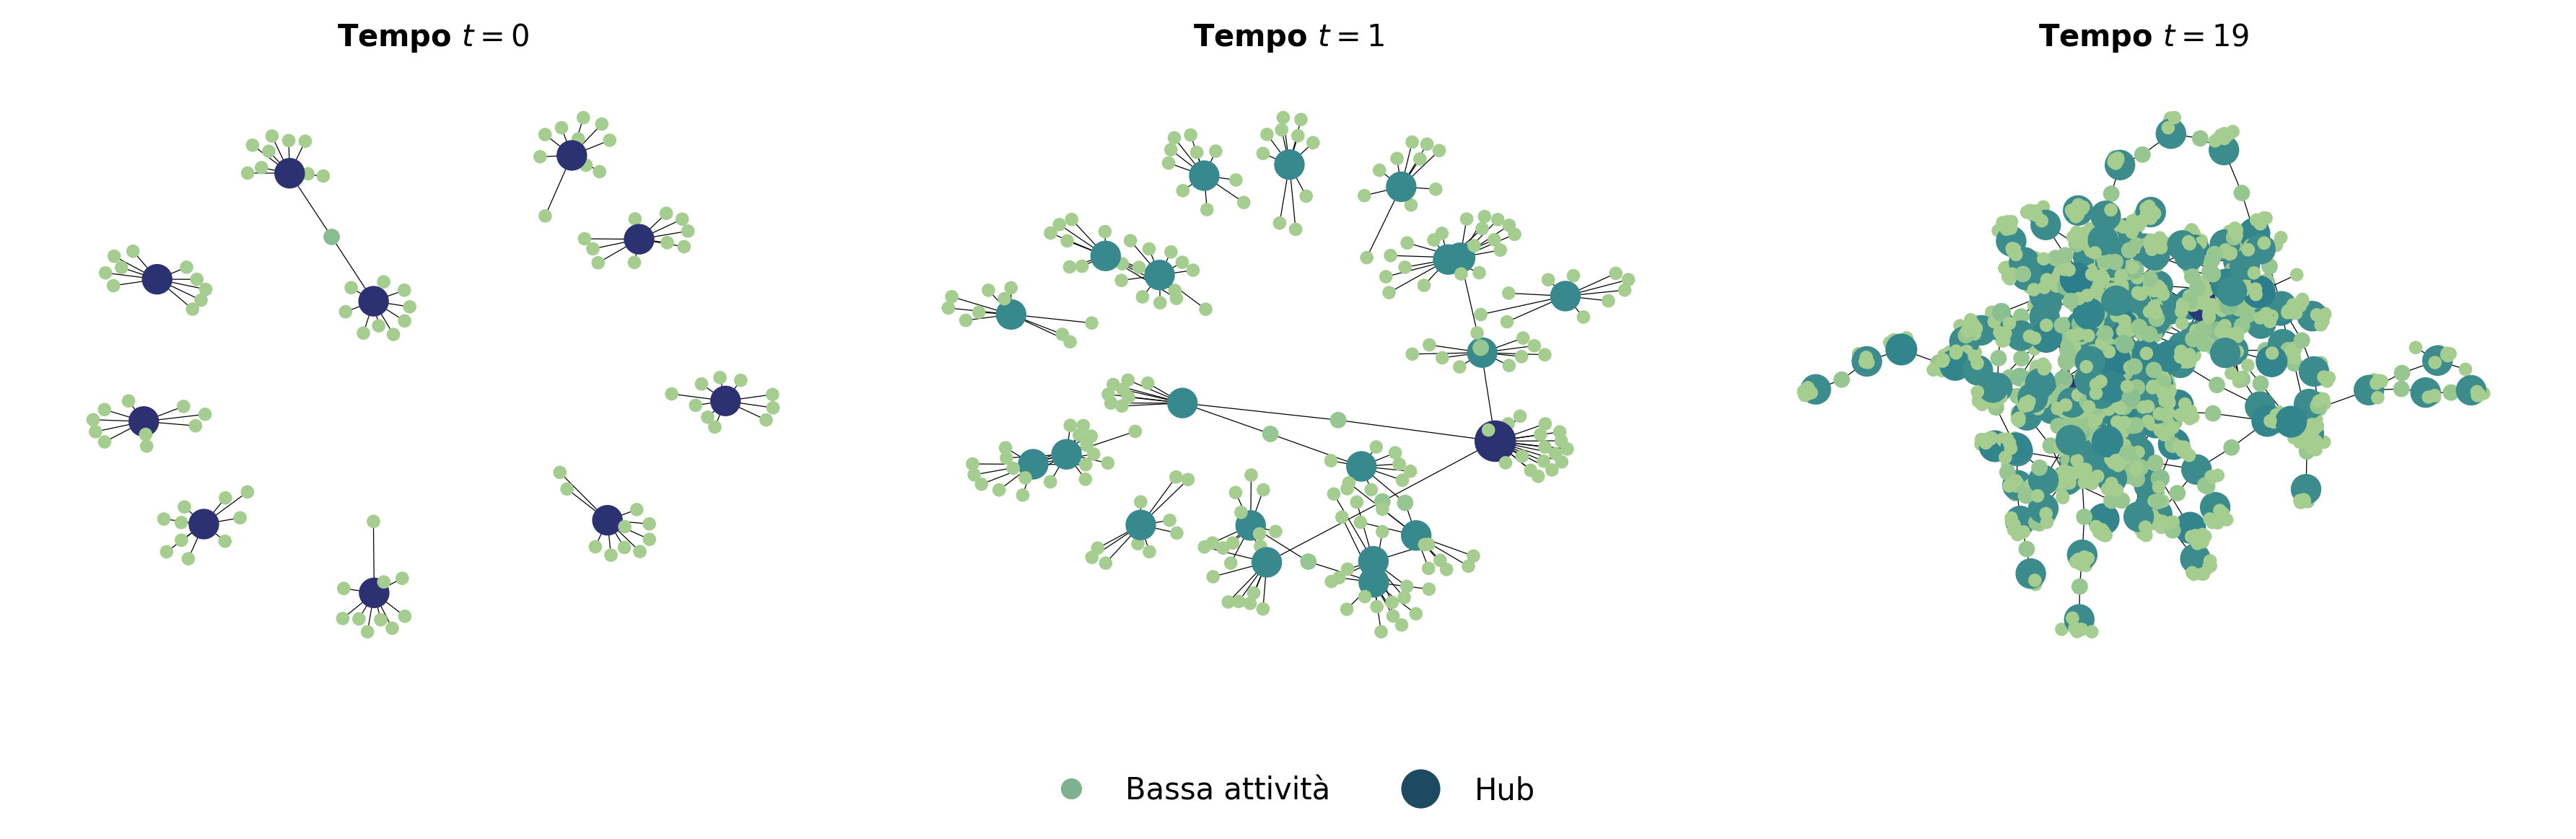

In [ ]:
G_tot_comm, Gs_comm, Gs_tot_comm = get_adn_network_community(T=20, N=6000, eps=10**-3, alpha=2.1, m=10, eta=0.9, community_size=2000)

fig, axes = plt.subplots(dpi=300, ncols=3, figsize=(12, 4), facecolor='white')

plot_active_network(G=Gs_tot_comm[0], ax=axes[0], k=0.15)
axes[0].set_title("Tempo $t = 0$", fontsize=10, fontweight='bold')

plot_active_network(G=Gs_tot_comm[1], ax=axes[1], k=0.15)
axes[1].set_title("Tempo $t = 1$", fontsize=10, fontweight='bold')

plot_active_network(G=Gs_tot_comm[19], ax=axes[2], k=0.15)
axes[2].set_title("Tempo $t = 19$", fontsize=10, fontweight='bold')

# LEGENDA
axes[1].plot([], [], 'o', color='#7eb28f', markersize=6, label='Bassa attività')
axes[1].plot([], [], 'o', color='#1d4a60', markersize=12, label='Hub')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)

plt.tight_layout()
plt.show()

# **Epidemic Spreding**

In [ ]:
def simulate_adn_community_epidemic(i0, N, mu, m, lambda_val, T, alpha, eps, eta, community_size):
    """
    Simulazione dell'epidemia attraverso il modello SIR su rete ADN
    con struttura a comunità. Le comunità hanno tutte la stessa popolazione
    per evitare rumore stocastico. L'infezione partirà da una comunità per
    verificare il ritardo della diffusione dell'epidemia in comunità diverse

    ----------
        @param i0: initial fraction of infected nodes
        @param N: total number of nodes
    ----------
    """

    activities = np.array([sample_activity(eps=eps, alpha=alpha) for i in range(N)])

    # Divisione in comunità
    num_communities = N // community_size
    communities = {c: [] for c in range(num_communities)}
    nodes_community_match = np.zeros(N, dtype=int)

    # Divisione dei nodi nelle comunità
    for i in range(N):
        c = i // community_size
        communities[c].append(i)
        nodes_community_match[i] = c


    # Inizializzazione Epidemia
    I_initial = int(i0 * N)
    if I_initial == 0: I_initial = 1
    infected = np.zeros(N)
    susceptible = np.ones(N)

    # Infezione dei pazienti zero solo in una comunità (comunità 0)
    pazienti_zero = np.random.choice(communities[0], I_initial, replace=False)
    infected[pazienti_zero] = 1
    susceptible[pazienti_zero] = 0

    incidence = []
    compartments = {"S": [N - I_initial], "I": [I_initial], "R": [0]}
    I_comm = {c: [np.sum(infected[communities[c]])] for c in range(num_communities)}


    for t in range(T):
        newI, newR = [], []
        for i in range(N):

            # Guarigione
            if infected[i] == 1 and np.random.rand() < mu:
                newR.append(i)

            # GENERAZIONE DELLA RETE ISTANTANEA E TRASMISSIONE
            # Se nodo attivo
            if np.random.rand() < activities[i]:
                # Link nella stessa comunità
                if np.random.rand() < eta:
                    rnd_neigh = sample_neighbours_community(i, m, communities[nodes_community_match[i]])
                # Link in comunità diversa
                else:
                    other_comms = [c for c in range(num_communities) if c != nodes_community_match[i]]
                    rnd_comm = np.random.choice(other_comms)
                    rnd_neigh = sample_neighbours_community(i, m, communities[rnd_comm])

                # Tentativo di contagio sui link generati
                for partner in rnd_neigh:
                    # Canale attivo di infezione
                    if infected[i] == 1 and susceptible[partner] == 1:
                        if np.random.rand() < lambda_val:
                            newI.append(partner)
                    # Canale passivo di infezione
                    elif susceptible[i] == 1 and infected[partner] == 1:
                        if np.random.rand() < lambda_val:
                            newI.append(i)

        # Aggiornamento stati
        for r in newR:
          if infected[r] == 1:
            infected[r] = 0

        for inf in np.unique(newI):
            if susceptible[inf] == 1:
                infected[inf] = 1
                susceptible[inf] = 0

        # Salvataggio Dati
        incidence.append(len(np.unique(newI)))
        compartments["S"].append(np.sum(susceptible))
        compartments["I"].append(np.sum(infected))
        compartments["R"].append(N - np.sum(susceptible) - np.sum(infected))

        # Conteggio numero di infetti per ogni comunità
        for c in range(num_communities):
            I_comm[c].append(np.sum(infected[communities[c]]))

    return incidence, compartments, I_comm

<>:32: SyntaxWarning: invalid escape sequence '\e'
<>:32: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_701/3287207738.py:32: SyntaxWarning: invalid escape sequence '\e'
  axes[1].set_title(f"Propagazione tra Comunità ($\eta={eta_epi}$)", fontweight='bold')


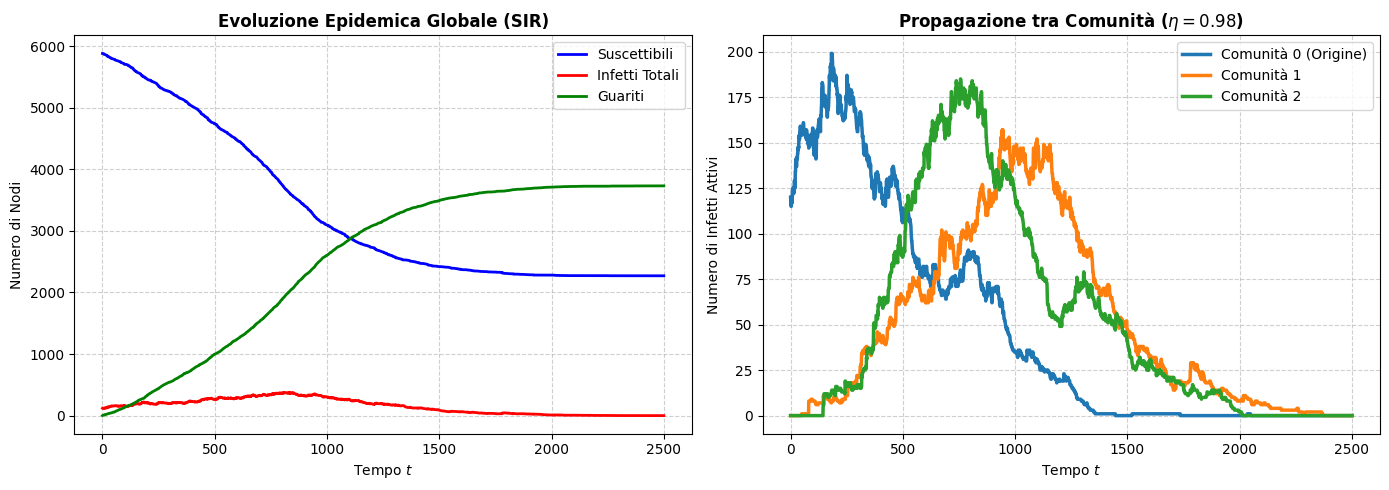

In [ ]:
T_epi = 2500
N_epi = 6000
size_comm = 2000
mu_val = 0.01        # Rate di guarigione
lambda_param = 0.50  # Rate di infezione
i0_frac = 0.02       # Frazione di infetti di partenza
m_epi = 10           # Numero di link generato per ogni nodo attivo
eta_epi = 0.98       # Segregazione delle comunità

incidenza, compartimenti, I_comunita = simulate_adn_community_epidemic(
    i0=i0_frac, N=N_epi, mu=mu_val, m=m_epi, lambda_val=lambda_param,
    T=T_epi, alpha=2.1, eps=10**-3, eta=eta_epi, community_size=size_comm
)


fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')

# Plot SIR Globale
axes[0].plot(compartimenti["S"], label='Suscettibili', color='blue', lw=2)
axes[0].plot(compartimenti["I"], label='Infetti Totali', color='red', lw=2)
axes[0].plot(compartimenti["R"], label='Guariti', color='green', lw=2)
axes[0].set_title("Evoluzione Epidemica Globale (SIR)", fontweight='bold')
axes[0].set_xlabel("Tempo $t$")
axes[0].set_ylabel("Numero di Nodi")
axes[0].legend()
axes[0].grid(True, ls='--', alpha=0.6)

# Plot Infetti per Singola Comunità
axes[1].plot(I_comunita[0], label='Comunità 0 (Origine)', color='#1f77b4', lw=2.5)
axes[1].plot(I_comunita[1], label='Comunità 1', color='#ff7f0e', lw=2.5)
axes[1].plot(I_comunita[2], label='Comunità 2', color='#2ca02c', lw=2.5)
axes[1].set_title(f"Propagazione tra Comunità ($\eta={eta_epi}$)", fontweight='bold')
axes[1].set_xlabel("Tempo $t$")
axes[1].set_ylabel("Numero di Infetti Attivi")
axes[1].legend()
axes[1].grid(True, ls='--', alpha=0.6)

plt.tight_layout()
plt.show()

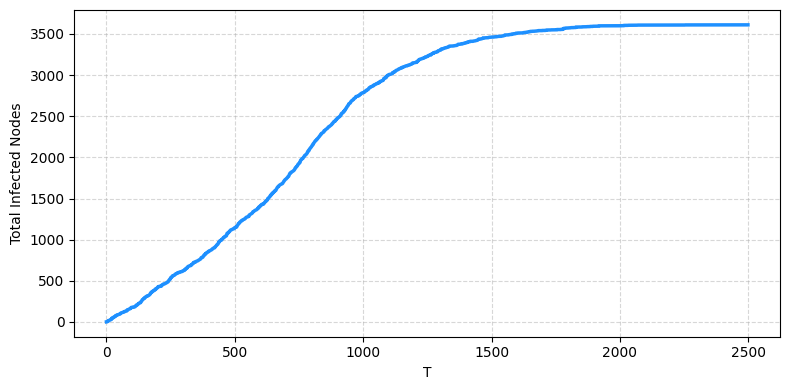

In [ ]:
# Plot incidenza cumulativa
fig, ax = plt.subplots(figsize=(8, 4), facecolor='white')

ax.plot(np.cumsum(incidenza), color="dodgerblue", lw=2.5)

ax.set_ylabel("Total Infected Nodes")
ax.set_xlabel("T")
ax.grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\e'
<>:20: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_701/619647726.py:20: SyntaxWarning: invalid escape sequence '\e'
  axes[idx].set_title(f"Forza Comunità: $\eta = {eta_test}$", fontweight='bold')


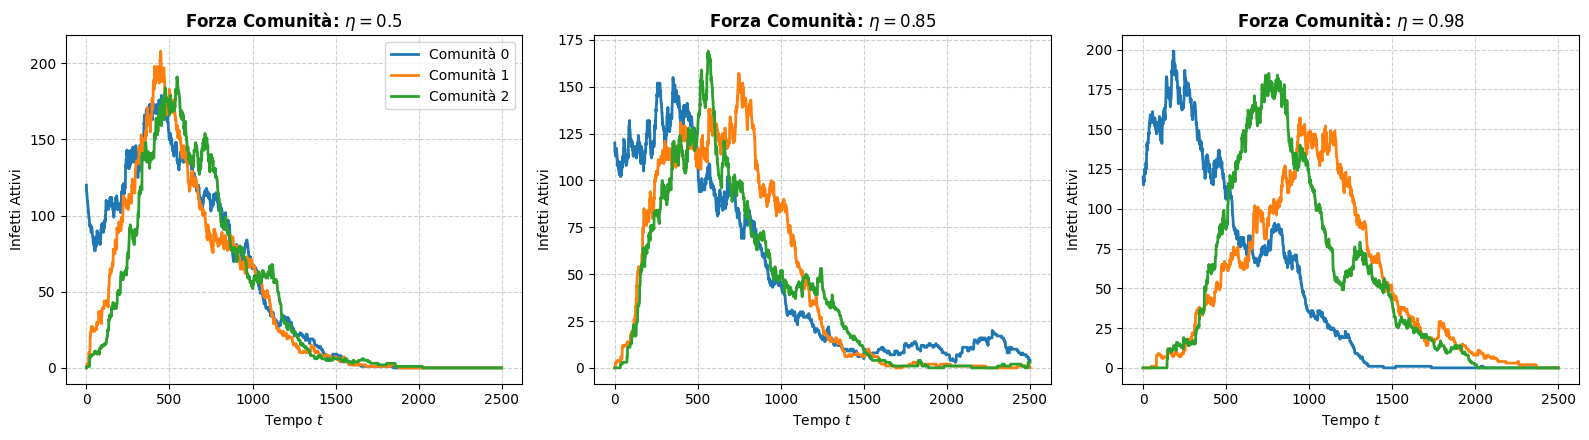

In [ ]:
# Effetto di eta sull'epidemia

etas = [0.50, 0.85, 0.98]
T_test = 2500

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), facecolor='white')

for idx, eta_test in enumerate(etas):

    _, _, I_comm_test = simulate_adn_community_epidemic(
        i0=i0_frac, N=N_epi, mu=mu_val, m=m_epi, lambda_val=lambda_param,
        T=T_test, alpha=2.1, eps=10**-3, eta=eta_test, community_size=size_comm
    )

    # Plot delle tre comunità per specifico eta
    axes[idx].plot(I_comm_test[0], label='Comunità 0', color='#1f77b4', lw=2)
    axes[idx].plot(I_comm_test[1], label='Comunità 1', color='#ff7f0e', lw=2)
    axes[idx].plot(I_comm_test[2], label='Comunità 2', color='#2ca02c', lw=2)

    axes[idx].set_title(f"Forza Comunità: $\eta = {eta_test}$", fontweight='bold')
    axes[idx].set_xlabel("Tempo $t$")
    axes[idx].set_ylabel("Infetti Attivi")
    if idx == 0:
        axes[idx].legend()
    axes[idx].grid(True, ls='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
def simulate_threshold_community(N, i0, mu, m, lambda_val, T, activities, eta, community_size):
    """
    Simula un'epidemia SIR su rete activity-driven temporale con struttura a comunità.
    Calcola rapidamente l'Attack Rate finale (frazione cumulativa di infetti).

    ----------
        @param N: numero totale di nodi nella rete (int)
        @param i0: frazione iniziale di infetti rispetto a N (float, es. 0.01 per 1%)
        @param mu: probabilità di guarigione per singolo tick (float)
        @param m: numero di contatti generati da ogni nodo attivo (int)
        @param lambda_val: probabilità di trasmissione per singolo contatto (float)
        @param T: numero massimo di istanti temporali di simulazione (int)
        @param activities: array di dimensione N contenente il tasso di attività a_i di ciascun nodo (np.ndarray)
        @param eta: mixing parameter; probabilità di interazione intra-comunità vs inter-comunità (float)
        @param community_size: numero di individui per ciascuna comunità (int)


    -------
    """

    # Inizializzazione stato di infetto e suscettibile
    infected = np.zeros(N)
    susceptible = np.ones(N)

    # Divisione in comunità deterministica
    num_communities = N // community_size
    communities = {c: [] for c in range(num_communities)}
    nodes_community_match = np.zeros(N, dtype=int)

    for i in range(N):
        c = i // community_size
        communities[c].append(i)
        nodes_community_match[i] = c

    # Inizializzazione pazienti zero confinati nella prima comunità
    I_initial = max(1, int(i0 * N))
    pazienti_zero = np.random.choice(communities[0], I_initial, replace=False)
    infected[pazienti_zero] = 1
    susceptible[pazienti_zero] = 0

    for t in range(T):

        newI, newR = [], []

        for i in np.where(infected == 1)[0]:
            if np.random.rand() < mu:
                newR.append(i)

        active_nodes = np.where(np.random.rand(N) < activities)[0]
        for i in active_nodes:
            if np.random.rand() < eta:
                targets = np.random.choice(communities[nodes_community_match[i]], m, replace=True)
            else:
                other_comms = [c for c in range(num_communities) if c != nodes_community_match[i]]
                rnd_comm = np.random.choice(other_comms)
                targets = np.random.choice(communities[rnd_comm], m, replace=True)


            for p in targets:
                if infected[i] == 1 and susceptible[p] == 1:
                    if np.random.rand() < lambda_val:
                        newI.append(p)
                elif susceptible[i] == 1 and infected[partner := p] == 1:
                    if np.random.rand() < lambda_val:
                        newI.append(i)

        for r in newR:
            infected[r] = 0

        for inf in np.unique(newI):
            if susceptible[inf] == 1:
                infected[inf] = 1
                susceptible[inf] = 0

    # Dimensione finale dell'epidemia: Attack Rate (R_inf / N)
    return (N - np.sum(susceptible)) / N


def build_integrated_community_network(N, m, T_int, activities, eta, community_size):
    """
    Crea una rete statica aggregata accumulando i link generati da un modello
    activity-driven con struttura a comunità per un intervallo temporale T_int.

    ----------
        @param N: numero totale di nodi nella rete (int)
        @param m: numero di link generati da ogni nodo attivo (int)
        @param T_int: numero di passi temporali per cui accumulare i link (int)
        @param activities: array con le probabilità di attivazione dei nodi (np.ndarray)
        @param eta: probabilità di creare link all'interno della propria comunità (float)
        @param community_size: dimensione di ciascuna comunità (int)


    """

    # Iniziazlizzazione Grafo
    G = nx.Graph()
    G.add_nodes_from(range(N))

    # Inizializzazione comunità
    num_communities = N // community_size
    communities = {c: [] for c in range(num_communities)}
    nodes_community_match = np.zeros(N, dtype=int)

    # Divisione dei nodi nelle comunità
    for i in range(N):
        c = i // community_size
        communities[c].append(i)
        nodes_community_match[i] = c

    for t in range(T_int):
        # Controllo nodi attivi
        active_nodes = np.where(np.random.rand(N) < activities)[0]

        for i in active_nodes:
            if np.random.rand() < eta:
                targets = np.random.choice(communities[nodes_community_match[i]], m, replace=True)

            else:
                other_comms = [c for c in range(num_communities) if c != nodes_community_match[i]]
                rnd_comm = np.random.choice(other_comms)
                targets = np.random.choice(communities[rnd_comm], m, replace=True)

            # Aggiunta link tra nodo attivo e nuovo nodo target
            for p in targets:
                if i != p: G.add_edge(i, p)
    return G

def simulate_static_network(G, mu, lambda_val, T, community_size):
    """
    Simula un'epidemia (modello SIR) su una rete topologica statica aggregata.
    Calcola l'Attack Rate finale della popolazione infettata.

    ----------
        @param G: grafo statico su cui simulare l'epidemia (nx.Graph)
        @param mu: probabilità di guarigione per singolo tick temporale (float)
        @param lambda_val: probabilità di trasmissione dell'infezione per link (float)
        @param T: numero massimo di passi temporali di simulazione (int)
        @param community_size: dimensione della prima comunità da cui estrarre i pazienti zero (int)

    """

    N = G.number_of_nodes()
    infected = np.zeros(N)
    susceptible = np.ones(N)

    # Inizializzazione pazienti zero confinati nella prima comunità
    I_initial = max(1, int(0.01 * N))
    pazienti_zero = np.random.choice(range(community_size), I_initial, replace=False)
    infected[pazienti_zero] = 1
    susceptible[pazienti_zero] = 0

    for t in range(T):
        if np.sum(infected) == 0:
            break

        newI, newR = [], []

        for i in np.where(infected == 1)[0]:
            if np.random.rand() < mu:
                newR.append(i)

            for neighbor in G.neighbors(i):
                if susceptible[neighbor] == 1 and np.random.rand() < lambda_val:
                    newI.append(neighbor)
        for r in newR:
            infected[r] = 0

        for inf in np.unique(newI):
            if susceptible[inf] == 1:
                infected[inf] = 1
                susceptible[inf] = 0

    return (N - np.sum(susceptible)) / N

Soglia teorica (lambda/mu): 3.8167


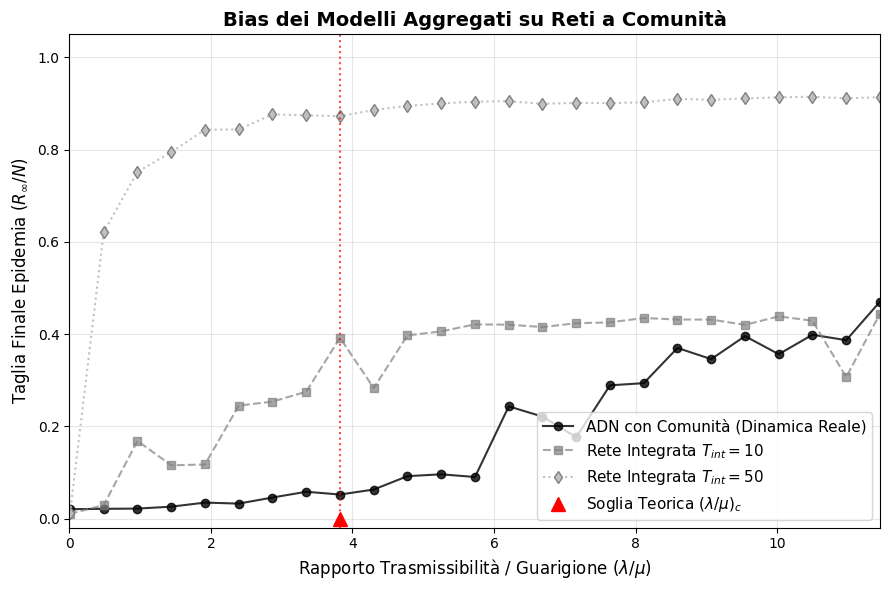

In [ ]:
T_epi = 2500
N_epi = 6000
size_comm = 2000
mu_val = 0.01
i0_frac = 0.02
m_epi = 10
eta_epi = 0.98


np.random.seed(42)
eps, alpha = 10**-3, 2.1
U = np.random.rand(N_epi)

activities = ((1.0 - eps**(1.0 - alpha)) * U + eps**(1.0 - alpha))**(1.0 / (1.0 - alpha))

# Calcolo analitico della soglia critica (lambda / mu)
den = m_epi * (np.mean(activities) + np.sqrt(np.mean(activities**2)))
soglia_ratio_c = 1.0 / den

print(f"Soglia teorica (lambda/mu): {soglia_ratio_c:.4f}")

# Reti statiche aggregate (timestep 10 e 50)
G_int_10 = build_integrated_community_network(N_epi, m_epi, 10, activities, eta_epi, size_comm)
G_int_50 = build_integrated_community_network(N_epi, m_epi, 50, activities, eta_epi, size_comm)


# DIAGRAMMA DI FASE
x_ratios = np.linspace(0.01, soglia_ratio_c * 3.0, 25)

res_dynamic, res_int_10, res_int_50 = [], [], []

for ratio in x_ratios:
    l_val = ratio * mu_val
    if l_val > 1.0:
        l_val = 1.0

    res_dynamic.append(simulate_threshold_community(
        N_epi, i0_frac, mu_val, m_epi, l_val, T_epi, activities, eta_epi, size_comm
    ))

    res_int_10.append(simulate_static_network(G_int_10, mu_val, l_val, T_epi, size_comm))
    res_int_50.append(simulate_static_network(G_int_50, mu_val, l_val, T_epi, size_comm))

# Plot
plt.figure(figsize=(9, 6), facecolor='white')

plt.plot(x_ratios, res_dynamic, 'o-', color='black', markersize=6, alpha=0.8, label='ADN con Comunità (Dinamica Reale)')
plt.plot(x_ratios, res_int_10, 's--', color='gray', markersize=6, alpha=0.7, label=r'Rete Integrata $T_{int}=10$')
plt.plot(x_ratios, res_int_50, 'd:', color='silver', markeredgecolor='gray', markersize=6, label=r'Rete Integrata $T_{int}=50$')
plt.axvline(soglia_ratio_c, color='red', linestyle=':', lw=1.5, alpha=0.7)
plt.plot(soglia_ratio_c, 0, '^', color='red', markersize=10, label=r'Soglia Teorica $(\lambda/\mu)_c$')

plt.title("Bias dei Modelli Aggregati su Reti a Comunità", fontsize=14, fontweight='bold')
plt.xlabel(r"Rapporto Trasmissibilità / Guarigione ($\lambda / \mu$)", fontsize=12)
plt.ylabel(r"Taglia Finale Epidemia ($R_{\infty}/N$)", fontsize=12)

plt.xlim(0, soglia_ratio_c * 3.0)
plt.ylim(-0.02, 1.05)
plt.legend(fontsize=11)
plt.grid(True, ls='-', alpha=0.3)
plt.tight_layout()
plt.show()

# **Immunization**

In [ ]:
def simulate_immunization(N, i0, mu, m, lambda_val, T, activities, eta, community_size, vaccinati):
    """
    Simula un'epidemia SIR su rete dinamica activity-driven a comunità, valutando
    l'efficacia di una strategia di immunizzazione (vaccinazione preventiva).

    ----------
        @param N: numero totale di nodi nella rete (int)
        @param i0: frazione iniziale di nodi infetti (pazienti zero) rispetto a N (float, es. 0.01)
        @param mu: probabilità di guarigione per singolo tick temporale (float)
        @param m: numero di link generati da ciascun nodo attivo (int)
        @param lambda_val: probabilità di trasmissione dell'infezione per contatto (float)
        @param T: numero massimo di tick temporali di simulazione (int)
        @param activities: array dei tassi di attività a_i dei nodi (np.ndarray)
        @param eta: mixing parameter; probabilità di interazione intra-comunità (float)
        @param community_size: dimensione fissa di ciascuna comunità (int)
        @param vaccinati: array o lista di indici dei nodi immunizzati prima dell'inizio (array-like)

    """
    # Inizializzazione stato di infetto e suscettibile
    infected = np.zeros(N)
    susceptible = np.ones(N)

    # Applicazione dell'immunizzazione
    if len(vaccinati) > 0:
        susceptible[vaccinati] = 0

    # Divisione in comunità
    num_communities = N // community_size
    communities = {c: [] for c in range(num_communities)}
    nodes_community_match = np.zeros(N, dtype=int)

    for i in range(N):
        c = i // community_size
        communities[c].append(i)
        nodes_community_match[i] = c

    # Nodi della prima comunità non vaccinati
    nodi_com_0_suscettibili = [n for n in communities[0] if susceptible[n] == 1]

    # Controllo se la prima comunità è tutta vaccinata
    if len(nodi_com_0_suscettibili) == 0:
        return 0.0

    # Inizializzazione pazienti zero
    I_initial = max(1, int(i0 * N))
    I_initial = min(I_initial, len(nodi_com_0_suscettibili))
    pazienti_zero = np.random.choice(nodi_com_0_suscettibili, I_initial, replace=False)

    infected[pazienti_zero] = 1
    susceptible[pazienti_zero] = 0

    # Suscettibili effettivi a t=0 (esclusi vaccinati e pazienti zero)
    S_initial_tot = np.sum(susceptible)

    for t in range(T):
        # Controllo assenza di infetti
        if np.sum(infected) == 0:
            break

        newI, newR = [], []

        # Processo di guarigione
        for i in np.where(infected == 1)[0]:
            if np.random.rand() < mu:
                newR.append(i)

        # Generazione contatti dinamici per nodi attivi
        active_nodes = np.where(np.random.rand(N) < activities)[0]
        for i in active_nodes:
            if np.random.rand() < eta:
                targets = np.random.choice(communities[nodes_community_match[i]], m, replace=True)
            else:
                other_comms = [c for c in range(num_communities) if c != nodes_community_match[i]]
                rnd_comm = np.random.choice(other_comms)
                targets = np.random.choice(communities[rnd_comm], m, replace=True)

            for p in targets:
                if i == p:
                    continue

                if infected[i] == 1 and susceptible[p] == 1:
                    if np.random.rand() < lambda_val:
                        newI.append(p)
                elif susceptible[i] == 1 and infected[p] == 1:
                    if np.random.rand() < lambda_val:
                        newI.append(i)

        # Aggiornamento sincrono degli stati
        for r in newR:
            infected[r] = 0

        for inf in np.unique(newI):
            if susceptible[inf] == 1:
                infected[inf] = 1
                susceptible[inf] = 0

    # Calcolo dell'Attack Rate finale sul totale della popolazione N
    return (S_initial_tot - np.sum(susceptible) + I_initial) / N


def build_observation_network(N, m, T_int, activities, eta, community_size):
    """
    Costruisce un grafo di contatti osservati in una finestra temporale limitata T_int.
    Utilizzato per implementare la strategia di vaccinazione basata sul Friendship Paradox
    (Acquaintance Immunization) senza richiedere la conoscenza globale della rete.

    ----------
        @param N: numero totale di nodi nella rete (int)
        @param m: numero di link generati da ogni nodo attivo per tick (int)
        @param T_int: finestra temporale di osservazione dei contatti (int)
        @param activities: array dei tassi di attività a_i dei nodi (np.ndarray)
        @param eta: mixing parameter; probabilità di connessione intra-comunità (float)
        @param community_size: dimensione di ciascuna comunità (int)

    """
    G = nx.Graph()
    G.add_nodes_from(range(N))

    num_communities = N // community_size
    communities = {c: [] for c in range(num_communities)}
    nodes_community_match = np.zeros(N, dtype=int)

    for i in range(N):
        c = i // community_size
        communities[c].append(i)
        nodes_community_match[i] = c

    for t in range(T_int):
        active_nodes = np.where(np.random.rand(N) < activities)[0]
        for i in active_nodes:
            if np.random.rand() < eta:
                targets = np.random.choice(communities[nodes_community_match[i]], m, replace=True)
            else:
                other_comms = [c for c in range(num_communities) if c != nodes_community_match[i]]
                rnd_comm = np.random.choice(other_comms)
                targets = np.random.choice(communities[rnd_comm], m, replace=True)

            for p in targets:
                if i != p:
                    G.add_edge(i, p)

    return G

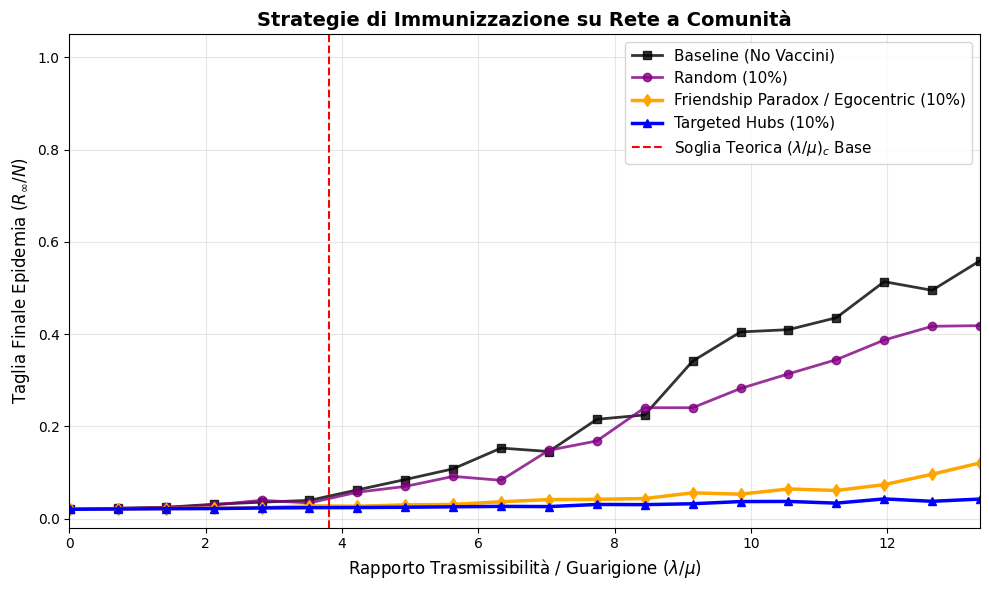

In [ ]:
T_epi = 2500
N_epi = 6000
size_comm = 2000
mu_val = 0.01
i0_frac = 0.02
m_epi = 10
eta_epi = 0.98
budget_vaccini = int(0.10 * N_epi)  # 10% della popolazione (600 vaccini)


np.random.seed(42)
eps, alpha = 10**-3, 2.1
U = np.random.rand(N_epi)

# Attività
activities = ((1.0 - eps**(1.0 - alpha)) * U + eps**(1.0 - alpha))**(1.0 / (1.0 - alpha))

# Soglia teorica
den = m_epi * (np.mean(activities) + np.sqrt(np.mean(activities**2)))
soglia_ratio_c = 1.0 / den

# Random Immunization
vaccini_random = np.random.choice(N_epi, budget_vaccini, replace=False)

# Targeted Immunization (nodi con attività maggiore)
vaccini_targeted = np.argsort(activities)[-budget_vaccini:]

# Acquaintance Immunization (Friendship Paradox su rete osservata per 20 giorni)
G_obs = build_observation_network(N_epi, m_epi, 20, activities, eta_epi, size_comm)

# Nodi che hanno avuto almeno un contatto
nodi_con_vicini = [n for n, deg in dict(G_obs.degree).items() if deg > 0]

# Ciclo necessario per arrivare a coprire tutto il budget vaccinale
vaccini_ego = set()
while len(vaccini_ego) < budget_vaccini:
    p = np.random.choice(nodi_con_vicini)
    vicini = list(G_obs.neighbors(p))
    vaccini_ego.add(np.random.choice(vicini))

vaccini_ego = list(vaccini_ego)

# Diagramma di fase
x_ratios = np.linspace(0.01, soglia_ratio_c * 3.5, 20)
res_base, res_rand, res_ego, res_targ = [], [], [], []

for ratio in x_ratios:
    l_val = min(ratio * mu_val, 1.0)

    # Media su 3 run per ridurre la varianza stocastica
    tmp_base, tmp_rand, tmp_ego, tmp_targ = [], [], [], []
    for _ in range(3):
        tmp_base.append(simulate_immunization(
            N_epi, i0_frac, mu_val, m_epi, l_val, T_epi, activities, eta_epi, size_comm, []
        ))
        tmp_rand.append(simulate_immunization(
            N_epi, i0_frac, mu_val, m_epi, l_val, T_epi, activities, eta_epi, size_comm, vaccini_random
        ))
        tmp_ego.append(simulate_immunization(
            N_epi, i0_frac, mu_val, m_epi, l_val, T_epi, activities, eta_epi, size_comm, vaccini_ego
        ))
        tmp_targ.append(simulate_immunization(
            N_epi, i0_frac, mu_val, m_epi, l_val, T_epi, activities, eta_epi, size_comm, vaccini_targeted
        ))

    res_base.append(np.mean(tmp_base))
    res_rand.append(np.mean(tmp_rand))
    res_ego.append(np.mean(tmp_ego))
    res_targ.append(np.mean(tmp_targ))

# Plot
plt.figure(figsize=(10, 6), facecolor='white')

plt.plot(x_ratios, res_base, 's-', color='black', alpha=0.8, lw=2, label='Baseline (No Vaccini)')
plt.plot(x_ratios, res_rand, 'o-', color='purple', alpha=0.8, lw=2, label='Random (10%)')
plt.plot(x_ratios, res_ego, 'd-', color='orange', lw=2.5, label='Friendship Paradox / Egocentric (10%)')
plt.plot(x_ratios, res_targ, '^-', color='blue', lw=2.5, label='Targeted Hubs (10%)')

plt.axvline(x=soglia_ratio_c, color='red', linestyle='--', label=r'Soglia Teorica $(\lambda/\mu)_c$ Base')

plt.title("Strategie di Immunizzazione su Rete a Comunità", fontsize=14, fontweight='bold')
plt.xlabel(r"Rapporto Trasmissibilità / Guarigione ($\lambda / \mu$)", fontsize=12)
plt.ylabel(r"Taglia Finale Epidemia ($R_{\infty}/N$)", fontsize=12)

plt.xlim(0, soglia_ratio_c * 3.5)
plt.ylim(-0.02, 1.05)
plt.legend(fontsize=11)
plt.grid(True, ls='-', alpha=0.3)
plt.tight_layout()
plt.show()

# **Real Dataset**

In [ ]:
"""
t tempo di contatto
i indice del primo studente
j indice del secondo studente
class_i classe del primo studente
class_j classe del secondo studente
"""
df = pd.read_csv('primaryschool.csv', sep='\t', header=None,
                 names=['t', 'i', 'j', 'class_i', 'class_j'])

cont_intra_class = df[df['class_i'] == df['class_j']].shape[0]
contatti_totali = df.shape[0]
eta_empirico = cont_intra_class / contatti_totali

print(f"Contatti Totali registrati: {contatti_totali}")
print(f"Valore di ETA (Segregazione empirica): {eta_empirico:.3f} ({eta_empirico*100:.1f}% intra-classe)")

nodi_unq = pd.unique(df[['i', 'j']].values.ravel('K'))
N_real = len(nodi_unq)
map_nodi = {id_originale: indice for indice, id_originale in enumerate(nodi_unq)}

# .map prende gli id dei bambini del dataset e li riassegna in ordine (0, 1, 2,..)
df['i_mapped'] = df['i'].map(map_nodi)
df['j_mapped'] = df['j'].map(map_nodi)
print(f"Popolazione scolastica (N): {N_real} studenti/insegnanti")

# Raggruppamento dei contatti istante per istante
contatti_raggruppati = df.groupby('t')

Contatti Totali registrati: 125773
Valore di ETA (Segregazione empirica): 0.726 (72.6% intra-classe)
Popolazione scolastica (N): 242 studenti/insegnanti


In [ ]:
def simulate_sir_empirical(contatti_per_tempo, N, mu, lambda_val, i0=0.02):
    """
    Simula un'epidemia SIR guidata direttamente dalla sequenza temporale di contatti
    reali ad alta risoluzione (dataset empirico SocioPatterns).

    ----------
        @param contatti_per_tempo: DataFrameGroupBy raggruppato sulla colonna temporale 't' (pd.core.groupby.DataFrameGroupBy)
        @param N: numero totale di individui unici registrati nel dataset (int)
        @param mu: probabilità di guarigione per singolo intervallo temporale delta_t (float)
        @param lambda_val: probabilità di trasmissione per singolo contatto da 20 secondi (float)
        @param i0: frazione iniziale di pazienti zero rispetto alla popolazione N (float, default=0.02)

    """
    # Inizializzazione infetti e suscettibili
    infected = np.zeros(N)
    susceptible = np.ones(N)

    # Si infetta il 2% della scuola (circa 5 persone su 242)
    I_initial = max(1, int(i0 * N))
    pazienti_zero = np.random.choice(N, I_initial, replace=False)
    infected[pazienti_zero] = 1
    susceptible[pazienti_zero] = 0

    # Otteniamo i tempi in ordine cronologico
    tempi_ordinati = sorted(contatti_per_tempo.groups.keys())

    for t in tempi_ordinati:
        # Controllo infetti
        if np.sum(infected) == 0:
            break

        # Inizializzazione contatti al tempo t e liste
        contatti_t = contatti_per_tempo.get_group(t)
        newI, newR = [], []

        # Controllo guarigione
        for n in np.where(infected == 1)[0]:
            if np.random.rand() < mu:
                newR.append(n)

        # Trasmissione attraverso i contatti avvenuti in quel range temporale
        for _, row in contatti_t.iterrows():
            # Estrazione ID mappati (0-241)
            u, v = int(row['i_mapped']), int(row['j_mapped'])

            # Contagio
            if infected[u] == 1 and susceptible[v] == 1:
                if np.random.rand() < lambda_val:
                    newI.append(v)
            elif susceptible[u] == 1 and infected[v] == 1:
                if np.random.rand() < lambda_val:
                    newI.append(u)

        # Aggiornamento degli stati
        for r in newR:
            infected[r] = 0
        for inf in np.unique(newI):
            if susceptible[inf] == 1:
                infected[inf] = 1
                susceptible[inf] = 0

    return (N - np.sum(susceptible)) / N


def simulate_threshold_community_school(N, i0, mu, m, lambda_val, T, activities, eta, community_size):
    """
    Simula un'epidemia SIR su rete activity-driven a comunità, allineando l'inizializzazione
    dei pazienti zero a livello globale su tutta la scuola (non confinati nella sola classe 0).

    Parameters
    ----------
        @param N: numero totale di individui (int)
        @param i0: frazione iniziale di infetti (float)
        @param mu: tasso di guarigione per step temporale (float)
        @param m: numero medio di contatti per step di attivazione (int)
        @param lambda_val: probabilità di trasmissione per contatto (float)
        @param T: durata temporale totale della simulazione (int)
        @param activities: array delle frequenze di attività reali per ciascun nodo (np.ndarray)
        @param eta: mixing parameter empirico intra-classe (float)
        @param community_size: dimensione media di una classe (int)

    Returns
    -------
        @return attack_rate: quota cumulativa di popolazione contagiata R_inf / N (float)
    """
    infected = np.zeros(N)
    susceptible = np.ones(N)

    # Divisione in classi/comunità
    num_communities = N // community_size
    communities = {c: [] for c in range(num_communities)}
    nodes_community_match = np.zeros(N, dtype=int)

    for i in range(N):
        c = min(i // community_size, num_communities - 1)
        communities[c].append(i)
        nodes_community_match[i] = c

    # Pazienti zero estratti uniformemente sull'intera scuola
    I_initial = max(1, int(i0 * N))
    pazienti_zero = np.random.choice(N, I_initial, replace=False)
    infected[pazienti_zero] = 1
    susceptible[pazienti_zero] = 0

    for t in range(T):
        if np.sum(infected) == 0:
            break

        newI, newR = [], []

        # Processo di guarigione
        for i in np.where(infected == 1)[0]:
            if np.random.rand() < mu:
                newR.append(i)

        # Generazione contatti dinamici per i nodi attivi
        active_nodes = np.where(np.random.rand(N) < activities)[0]
        for i in active_nodes:
            current_comm = nodes_community_match[i]

            # Contatto intra-classe
            if np.random.rand() < eta or len(communities[current_comm]) <= 1:
                pool = [n for n in communities[current_comm] if n != i]
                targets = np.random.choice(pool, m, replace=True)
            # Contatto inter-classe (corridoio, mensa, cortile)
            else:
                other_comms = [c for c in range(num_communities) if c != current_comm]
                rnd_comm = np.random.choice(other_comms)
                targets = np.random.choice(communities[rnd_comm], m, replace=True)

            for p in targets:
                if i == p:
                    continue

                if infected[i] == 1 and susceptible[p] == 1:
                    if np.random.rand() < lambda_val:
                        newI.append(p)
                elif susceptible[i] == 1 and infected[p] == 1:
                    if np.random.rand() < lambda_val:
                        newI.append(i)

        for r in newR:
            infected[r] = 0

        for inf in np.unique(newI):
            if susceptible[inf] == 1:
                infected[inf] = 1
                susceptible[inf] = 0

    return (N - np.sum(susceptible)) / N


# Valori bassi per il range temporale basso
mu_test = 0.005
lambda_test = 0.05

taglia_finale = simulate_sir_empirical(contatti_raggruppati, N_real, mu_test, lambda_test)

print(f"Con mu={mu_test} e lambda={lambda_test}, l'epidemia ha infettato il {taglia_finale*100:.1f}% della scuola.")

Con mu=0.005 e lambda=0.05, l'epidemia ha infettato il 77.3% della scuola.


- Attività media reale <a_i>: 0.2330
- Grado di contatto medio m: 1
- Frazione intra-classe eta: 0.726
Completato Lambda = 0.001
Completato Lambda = 0.012
Completato Lambda = 0.023
Completato Lambda = 0.033
Completato Lambda = 0.044
Completato Lambda = 0.055
Completato Lambda = 0.066
Completato Lambda = 0.077
Completato Lambda = 0.088
Completato Lambda = 0.098
Completato Lambda = 0.109
Completato Lambda = 0.120


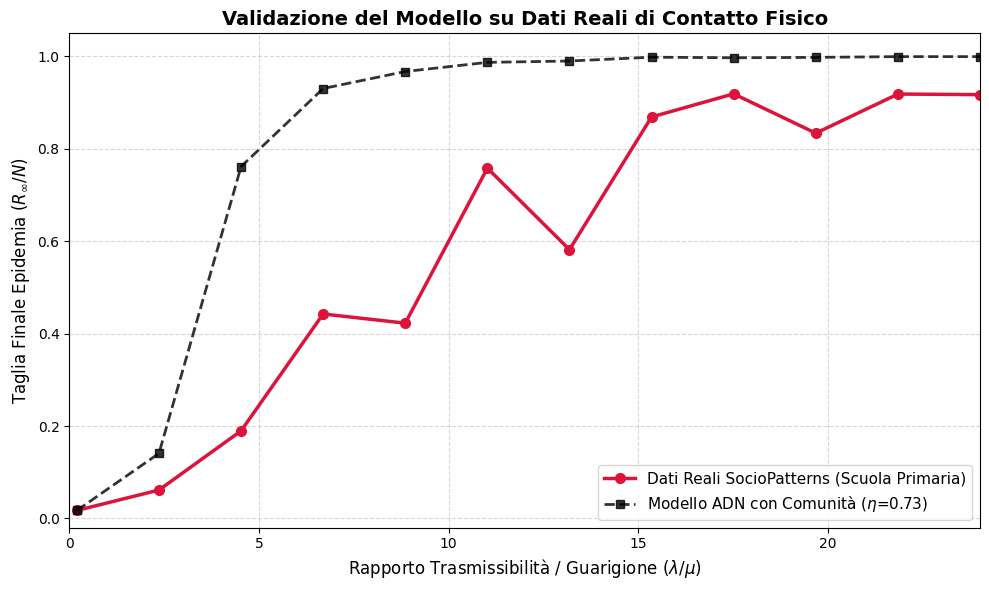

In [ ]:
N_scuola = N_real
T_scuola = len(contatti_raggruppati)
size_comm_scuola = 22             # Media 22 studenti per classe
eta_scuola = eta_empirico
mu_sim = 0.005
i0_scuola = 0.02

# Calcolo empirico dei tassi di attività a_i per ciascun nodo
df_presenze = pd.concat([
    df[['t', 'i_mapped']].rename(columns={'i_mapped': 'nodo'}),
    df[['t', 'j_mapped']].rename(columns={'j_mapped': 'nodo'})
]).drop_duplicates()

attivita_empiriche = np.zeros(N_scuola)
conteggio_presenze = df_presenze.groupby('nodo')['t'].nunique()
for nodo_idx, conteggio in conteggio_presenze.items():
    attivita_empiriche[nodo_idx] = conteggio / T_scuola

# Stima del numero medio di link m per evento di contatto
gradi_per_istante = df.groupby(['t', 'i_mapped']).size()
m_scuola = max(1, int(np.round(gradi_per_istante.mean())))

print(f"- Attività media reale <a_i>: {np.mean(attivita_empiriche):.4f}")
print(f"- Grado di contatto medio m: {m_scuola}")
print(f"- Frazione intra-classe eta: {eta_scuola:.3f}")



# Diagramma di fase
x_lambdas = np.linspace(0.001, 0.12, 12)

res_empirici = []
res_modello = []

for l_val in x_lambdas:
    tmp_emp = []
    tmp_mod = []

    for _ in range(10):
        # Diffusione su rete SocioPatterns
        tmp_emp.append(simulate_sir_empirical(
            contatti_raggruppati, N_scuola, mu_sim, l_val, i0=i0_scuola
        ))

        # Diffusione sul modello ADN con comunità
        tmp_mod.append(simulate_threshold_community_school(
            N=N_scuola, i0=i0_scuola, mu=mu_sim, m=m_scuola, lambda_val=l_val,
            T=T_scuola, activities=attivita_empiriche, eta=eta_scuola,
            community_size=size_comm_scuola
        ))

    res_empirici.append(np.mean(tmp_emp))
    res_modello.append(np.mean(tmp_mod))
    print(f"Completato Lambda = {l_val:.3f}")



# Plot
plt.figure(figsize=(10, 6), facecolor='white')

# Dati Reali
plt.plot(x_lambdas / mu_sim, res_empirici, 'o-', color='crimson', lw=2.5, markersize=7,
         label='Dati Reali SocioPatterns (Scuola Primaria)')

# Modello ADN
plt.plot(x_lambdas / mu_sim, res_modello, 's--', color='black', lw=2, markersize=6, alpha=0.8,
         label=rf'Modello ADN con Comunità ($\eta$={eta_scuola:.2f})')

plt.title("Validazione del Modello su Dati Reali di Contatto Fisico", fontsize=14, fontweight='bold')
plt.xlabel(r"Rapporto Trasmissibilità / Guarigione ($\lambda / \mu$)", fontsize=12)
plt.ylabel(r"Taglia Finale Epidemia ($R_{\infty}/N$)", fontsize=12)

plt.xlim(0, max(x_lambdas / mu_sim))
plt.ylim(-0.02, 1.05)
plt.legend(fontsize=11)
plt.grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.show()